In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import torch.optim as optim

PROJECT_DIR = '~/github/reddit-sentiment-analysis'

In [2]:
df_posts = pd.read_csv(f'{PROJECT_DIR}/data/preprocessed_data/preprocessed_titles.csv')
df_posts = df_posts[['subreddit', 'title']]
df_posts.head()

,subreddit,title
0,AskReddit,bad possible reply im pregnant
1,AskReddit,personal story dont tell sound make
2,AskReddit,person class become rich
3,AskReddit,worst reply “i’m leave you”
4,AskReddit,who dangerous human alive right


# 1. Feature Extraction
References:
1. https://medium.com/@hckecommerce/essential-nlp-feature-extraction-methods-1ff7cb4dc9f1
2. https://medium.com/@eskandar.sahel/exploring-feature-extraction-techniques-for-natural-language-processing-46052ee6514

## 1.1 Count Vectorization
- Convert text into numerical vectors based on frequency of words in the documents

### 1.1.1 Bag of Words (BOW)
#### 1.1.1.1. Bag of Unigrams

In [4]:
# Initialize the CountVectorizer
# lowercase converts all words into lowercase
# stop_words removes the stop words that are meaningless for topic classification
# ngram_range specifies the tokens are unigram (single word)
count_vectorizer = CountVectorizer(lowercase=True, stop_words='english', ngram_range=(1, 1), max_features=5000)

# Fit and transform the text data to a sparse matrix of word counts
bow_vector = count_vectorizer.fit_transform(df_posts['title'])

# Convert the BOW matrix into a dataframe whose columns are the tokens
unigrams_df = pd.DataFrame(data=bow_vector.toarray(), columns=count_vectorizer.get_feature_names_out())
unigrams_df = unigrams_df

unigrams_df.info()
unigrams_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4135 entries, 0 to 4134
Columns: 5000 entries, 03 to ºc
dtypes: int64(5000)
memory usage: 157.7 MB


,03,05,10,100,1000,10000,100000,100m,100th,100yearold,...,zimmer,zion,zombie,zone,zootopia,zorro,zoë,zuckerberg,zvonareva,ºc
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# 1.2. Word2Vec

# 2. Models
## 2.1. Supervised Learning
### 2.1.1. Softmax Regression
cross entropy loss
softmax function
gradient descent

In [177]:
X = unigrams_df
y = df_posts[['subreddit']]

# One-hot encode the target
onehot_encoder = OneHotEncoder(drop=None, sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y)  # Input should be 2-dim

# Split dataset into training, validation, and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y_onehot, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# Define directories for saving results
model_name = "softmax_regression"
results_dir = f"../results/{model_name}/"
os.makedirs(results_dir, exist_ok=True)

# Define model hyperparameters
input_dim = X_train.shape[1]
output_dim = y_train.shape[1]  # Number of classes
learning_rate = 0.01
epochs = 5
batch_size = 32

# Step 1: Build the model
model = tf.keras.Sequential([
    tf.keras.layers.InputLayer(input_shape=(input_dim,)),
    tf.keras.layers.Dense(output_dim, activation='softmax')  # Softmax layer
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss='categorical_crossentropy',  # Use cross-entropy for one-hot encoded labels
    metrics=['accuracy']
)

# Step 2: Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)

# Step 3: Draw learning curve
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Learning Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.savefig(f"{results_dir}/learning_curve.png")
plt.close()

# Step 4: Print and save hyperparameters
hyperparams = {
    "input_dim": input_dim,
    "output_dim": output_dim,
    "learning_rate": learning_rate,
    "epochs": epochs,
    "batch_size": batch_size
}
with open(f"{results_dir}/hyperparameters.txt", "w") as f:
    for key, value in hyperparams.items():
        f.write(f"{key}: {value}\n")

# Step 5: Generate classification reports
datasets = [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]

for name, X, y in datasets:
    # Get the class labels from the OneHotEncoder
    class_labels = onehot_encoder.get_feature_names_out(['subreddit'])
    class_labels = [i.replace('subreddit_', '') for i in class_labels]

    y_pred_probs = model.predict(X)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(y, axis=1)  # Convert one-hot to class labels for the report
    report = classification_report(y_true, y_pred, target_names=class_labels)
    with open(f"{results_dir}/{name.lower()}_classification_report.txt", "w") as f:
        f.write(f"Classification Report for {name} Set:\n")
        f.write(report)

    # Compute AUC (using the true labels and predicted probabilities)
    auc = roc_auc_score(y, y_pred_probs, average='macro', multi_class='ovr')
    print(f'AUC: {auc}')


print(f"Results saved in: {results_dir}")

Epoch 1/5


/opt/homebrew/anaconda3/lib/python3.10/site-packages/keras/src/layers/core/input_layer.py:26: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4557 - loss: 2.0542 - val_accuracy: 0.7485 - val_loss: 1.4387
Epoch 2/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 942us/step - accuracy: 0.9337 - loss: 0.9755 - val_accuracy: 0.7823 - val_loss: 1.1232
Epoch 3/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9630 - loss: 0.5715 - val_accuracy: 0.7739 - val_loss: 0.9907
Epoch 4/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 886us/step - accuracy: 0.9741 - loss: 0.4069 - val_accuracy: 0.7811 - val_loss: 0.9195
Epoch 5/5
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 873us/step - accuracy: 0.9735 - loss: 0.3024 - val_accuracy: 0.7848 - val_loss: 0.8737
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 531us/step
AUC: 0.9997532371798601
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 728us/step
AUC: 0.9621006235409215
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 454us/step
AUC: 0.961047454071184
Results saved in: ../results/softmax_regression/


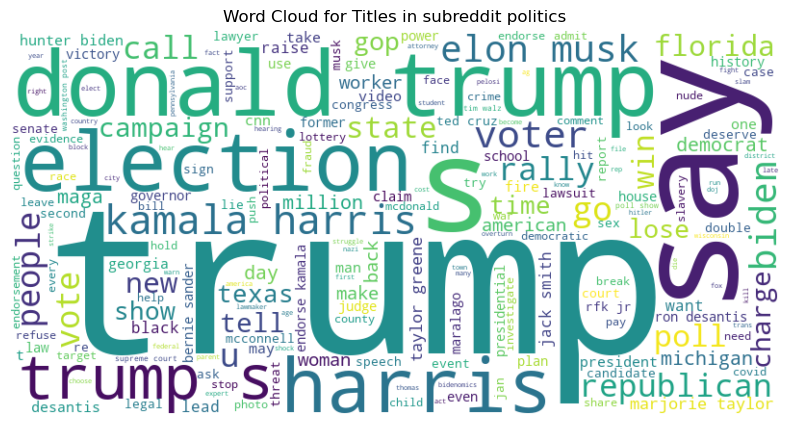

In [178]:
from wordcloud import WordCloud

subreddit = 'politics'

# Extract the titles for the first `n` rows
titles = df_posts.loc[df_posts['subreddit'] == subreddit, 'title']

# Join all titles into a single string
text = ' '.join(titles)

# Create the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

# Plot the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title(f"Word Cloud for Titles in subreddit {subreddit}")
plt.show()


### 2.1.2. SVM + Linear Kernel

In [179]:
import tensorflow as tf
from keras import layers, models
from keras.optimizers import Adam
from sklearn.model_selection import train_test_split, GridSearchCV
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Assuming X, y (one-hot encoded) are the input features and labels

# Create a simple model simulating SVM with a linear kernel
def create_svm_model(input_dim, C=1.0):
    model = models.Sequential()
    model.add(layers.Dense(10, input_dim=input_dim, activation='linear'))  # Linear kernel approximation (SVM)
    model.add(layers.Dense(10, activation='linear'))  # Output layer with linear activation for SVM
    model.compile(optimizer=Adam(), loss=tf.keras.losses.Hinge(), metrics=['accuracy'])
    return model

In [180]:
# Split data into training, validation, and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# Define parameter grid for hyperparameter tuning
param_grid = {
    'C': [0.0001, 0.001, 0.01, 1, 10],  # Regularization strength
}

# Function to evaluate model using GridSearchCV
def tune_svm_hyperparameters(X_train, y_train, param_grid):
    best_accuracy = 0
    best_params = {}
    for C in param_grid['C']:
        model = create_svm_model(X_train.shape[1], C)
        model.fit(X_train, y_train, epochs=100, batch_size=32, verbose=0)  # Train for 10 epochs
        accuracy = model.evaluate(X_val, y_val, verbose=0)[1]
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_params = {'C': C}
    return best_params, best_accuracy

# Perform hyperparameter tuning
best_params, best_accuracy = tune_svm_hyperparameters(X_train, y_train, param_grid)
print("Best hyperparameters:", best_params)


/opt/homebrew/anaconda3/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/opt/homebrew/anaconda3/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/opt/homebrew/anaconda3/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=

Best hyperparameters: {'C': 1}


In [181]:
# Train the model with best hyperparameters found
best_C = best_params['C']
final_model = create_svm_model(X_train.shape[1], C=best_C)

# Train the model
final_model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val))


Epoch 1/100


/opt/homebrew/anaconda3/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1313 - loss: 0.9874 - val_accuracy: 0.1084 - val_loss: 0.9508
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1857 - loss: 0.9114 - val_accuracy: 0.1024 - val_loss: 0.8879
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2363 - loss: 0.8153 - val_accuracy: 0.1205 - val_loss: 0.8079
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1700 - loss: 0.7098 - val_accuracy: 0.1084 - val_loss: 0.7109
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2102 - loss: 0.5656 - val_accuracy: 0.0904 - val_loss: 0.6089
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1942 - loss: 0.4688 - val_accuracy: 0.0964 - val_loss: 0.5176
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1580 - loss: 0.3860 - val_accuracy: 0.0964 - val_loss: 0.4473
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1682 - loss: 0.3218 - val_accuracy: 0.0964 - val_loss: 0.3

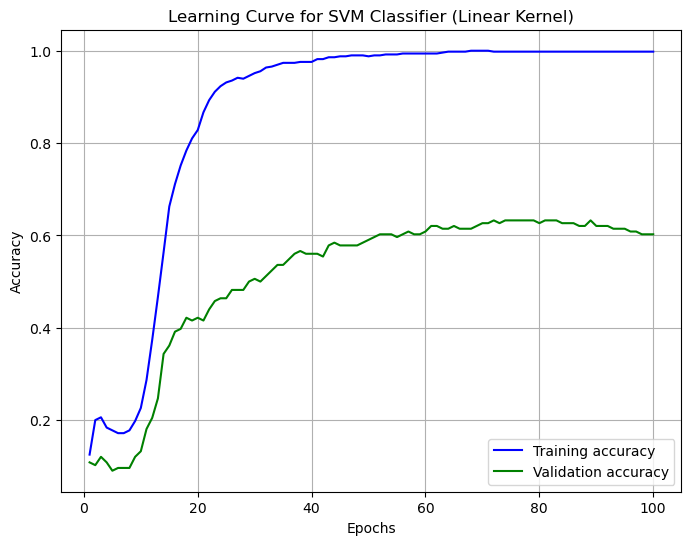

In [182]:
# Retrieve the training and validation accuracy for the learning curve
history = final_model.history.history
train_accuracy = history['accuracy']
val_accuracy = history['val_accuracy']
epochs = range(1, len(train_accuracy) + 1)

# Plot the learning curve
plt.figure(figsize=(8, 6))
plt.plot(epochs, train_accuracy, label='Training accuracy', color='blue')
plt.plot(epochs, val_accuracy, label='Validation accuracy', color='green')
plt.title("Learning Curve for SVM Classifier (Linear Kernel)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc='best')
plt.grid(True)
plt.show()


In [183]:
# Save the best hyperparameters to a DataFrame
hyperparameters_df = pd.DataFrame(best_params, index=[0])
print("Best Hyperparameters:")
print(hyperparameters_df)


Best Hyperparameters:
   C
0  1


In [184]:
# Predict and generate the classification reports for each dataset
y_train_pred = final_model.predict(X_train)
y_val_pred = final_model.predict(X_val)
y_test_pred = final_model.predict(X_test)

# Convert predicted probabilities to class labels
y_train_pred = np.argmax(y_train_pred, axis=1)
y_val_pred = np.argmax(y_val_pred, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# Generate classification reports
train_report = classification_report(np.argmax(y_train, axis=1), y_train_pred, output_dict=True, target_names=class_labels)
val_report = classification_report(np.argmax(y_val, axis=1), y_val_pred, output_dict=True, target_names=class_labels)
test_report = classification_report(np.argmax(y_test, axis=1), y_test_pred, output_dict=True, target_names=class_labels)

# Convert reports to DataFrames for easy viewing
train_report_df = pd.DataFrame(train_report).transpose()
val_report_df = pd.DataFrame(val_report).transpose()
test_report_df = pd.DataFrame(test_report).transpose()

# Print classification reports
print("Training Set Classification Report:")
print(train_report_df)
print("Validation Set Classification Report:")
print(val_report_df)
print("Test Set Classification Report:")
print(test_report_df)


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 610us/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 543us/step
Training Set Classification Report:
                   precision   recall  f1-score    support
AskReddit           0.981481  1.00000  0.990654   53.00000
books               1.000000  0.98000  0.989899   50.00000
explainlikeimfive   1.000000  1.00000  1.000000   53.00000
gaming              1.000000  1.00000  1.000000   57.00000
movies              1.000000  1.00000  1.000000   37.00000
politics            1.000000  1.00000  1.000000   38.00000
science             1.000000  1.00000  1.000000   57.00000
sports              1.000000  1.00000  1.000000   52.00000
technology          1.000000  1.00000  1.000000   52.00000
worldnews           1.000000  1.00000  1.000000   46.00000
accuracy            0.997980  0.99798  0.997980    0.99798
macro avg           0.998148  0.99800  0.998055  495.00000
weighted avg        0.998017  0.99798  0.997979  495.00000
Validation Set Class

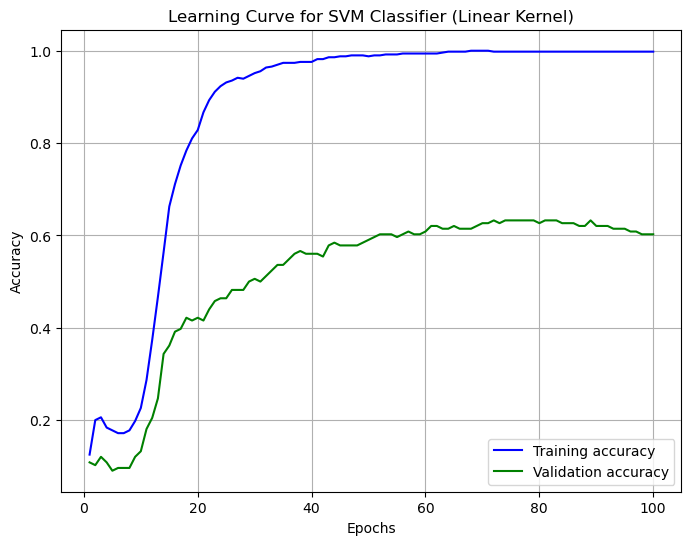

In [185]:
import os

# Create the directory to save results
model_name = 'svm_linear_kernel_tf'
results_dir = f"../results/{model_name}/"
os.makedirs(results_dir, exist_ok=True)

# Save the learning curve plot
plt.figure(figsize=(8, 6))
plt.plot(epochs, train_accuracy, label='Training accuracy', color='blue')
plt.plot(epochs, val_accuracy, label='Validation accuracy', color='green')
plt.title("Learning Curve for SVM Classifier (Linear Kernel)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc='best')
plt.grid(True)
plt.savefig(f"{results_dir}/learning_curve.png")

# Save the hyperparameters table
hyperparameters_df.to_csv(f"{results_dir}/hyperparameters.csv", index=False)

# Save the classification reports
train_report_df.to_csv(f"{results_dir}/train_classification_report.csv", index_label='class')
val_report_df.to_csv(f"{results_dir}/val_classification_report.csv", index_label='class')
test_report_df.to_csv(f"{results_dir}/test_classification_report.csv", index_label='class')


### 2.1.3. SVM + RBF Kernel

In [186]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report
import os

# Assuming you have X and y data already prepared
# X = Features (unigrams_df or similar)
# y = One-hot encoded labels (e.g., from df_posts[['subreddit']])

# Convert one-hot encoded labels to single class labels for SVM
y_class_labels = np.argmax(y, axis=1)

# 1. Split dataset into training, validation, and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y_class_labels, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# 2. Hyperparameter tuning using GridSearchCV
param_grid = {
    'C': [0.1, 1, 10, 20],  # Regularization strength
    'gamma': [0.1, 1, 10],  # Kernel coefficient
    'kernel': ['rbf']  # RBF Kernel
}

# Use GridSearchCV for hyperparameter tuning
svm = SVC()
grid_search = GridSearchCV(svm, param_grid, cv=5, scoring='accuracy', verbose=1, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best hyperparameters from GridSearchCV
best_params = grid_search.best_params_
best_accuracy = grid_search.best_score_
print("Best Hyperparameters:", best_params)
print("Best Cross-Validation Accuracy:", best_accuracy)

# 3. Train the final model with the best hyperparameters
final_svm = SVC(C=best_params['C'], gamma=best_params['gamma'], kernel=best_params['kernel'])
final_svm.fit(X_train, y_train)

# 5. Generate Classification Reports
# Predictions for the train, validation, and test sets
y_train_pred = final_svm.predict(X_train)
y_val_pred = final_svm.predict(X_val)
y_test_pred = final_svm.predict(X_test)

# Generate classification reports
train_report = classification_report(y_train, y_train_pred, output_dict=True, target_names=class_labels)
val_report = classification_report(y_val, y_val_pred, output_dict=True, target_names=class_labels)
test_report = classification_report(y_test, y_test_pred, output_dict=True, target_names=class_labels)

# Convert reports to DataFrames for easy viewing
train_report_df = pd.DataFrame(train_report).transpose()
val_report_df = pd.DataFrame(val_report).transpose()
test_report_df = pd.DataFrame(test_report).transpose()

# Print classification reports
print("Training Set Classification Report:")
print(train_report_df)
print("Validation Set Classification Report:")
print(val_report_df)
print("Test Set Classification Report:")
print(test_report_df)

# 6. Save Results to Directory
model_name = 'svm_rbf_kernel_sklearn'
results_dir = f"../results/{model_name}/"
os.makedirs(results_dir, exist_ok=True)

# Save the hyperparameters table
hyperparameters_df = pd.DataFrame(best_params, index=[0])
hyperparameters_df.to_csv(f"{results_dir}/hyperparameters.csv", index=False)

# Save the classification reports
train_report_df.to_csv(f"{results_dir}/train_classification_report.csv", index_label='class')
val_report_df.to_csv(f"{results_dir}/val_classification_report.csv", index_label='class')
test_report_df.to_csv(f"{results_dir}/test_classification_report.csv", index_label='class')


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Hyperparameters: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.6040404040404039
Training Set Classification Report:
                   precision  recall  f1-score  support
AskReddit                1.0     1.0       1.0     53.0
books                    1.0     1.0       1.0     50.0
explainlikeimfive        1.0     1.0       1.0     53.0
gaming                   1.0     1.0       1.0     57.0
movies                   1.0     1.0       1.0     37.0
politics                 1.0     1.0       1.0     38.0
science                  1.0     1.0       1.0     57.0
sports                   1.0     1.0       1.0     52.0
technology               1.0     1.0       1.0     52.0
worldnews                1.0     1.0       1.0     46.0
accuracy                 1.0     1.0       1.0      1.0
macro avg                1.0     1.0       1.0    495.0
weighted avg             1.0     1.0       1.0    495.0
Valid

### 2.1.4. Random Forest

In [191]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report
from sklearn.preprocessing import OneHotEncoder
import os

X = unigrams_df
y = df_posts[['subreddit']]

# One-hot encode the target
onehot_encoder = OneHotEncoder(drop=None, sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y)  # Input should be 2-dim

# Convert one-hot encoded labels to class labels (for RandomForest)
y_class_labels = np.argmax(y_onehot, axis=1)  # Get the index of the max value (class)

# 1. Split dataset into training, validation, and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y_class_labels, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# 2. Hyperparameter tuning using GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],  # Number of trees
    'max_depth': [None, 10, 20, 30],  # Maximum depth of each tree
    'min_samples_split': [2, 5, 10],  # Minimum number of samples required to split a node
    'min_samples_leaf': [1, 2, 4],    # Minimum number of samples required to be at a leaf node
    'bootstrap': [True, False]        # Whether bootstrap samples are used
}

# Use GridSearchCV for hyperparameter tuning
rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

# Best hyperparameters from GridSearchCV
best_params = grid_search.best_params_
best_accuracy = grid_search.best_score_
print("Best Hyperparameters:", best_params)
print("Best Cross-Validation Accuracy:", best_accuracy)

# 3. Train the final model with the best hyperparameters
final_rf = RandomForestClassifier(**best_params, random_state=42)
final_rf.fit(X_train, y_train)

rf_iter = RandomForestClassifier(**best_params, random_state=42)
rf_iter.fit(X_train, y_train)

# 5. Generate Classification Reports
# Predictions for the train, validation, and test sets
y_train_pred = final_rf.predict(X_train)
y_val_pred = final_rf.predict(X_val)
y_test_pred = final_rf.predict(X_test)

# Generate classification reports
train_report = classification_report(y_train, y_train_pred, output_dict=True)
val_report = classification_report(y_val, y_val_pred, output_dict=True)
test_report = classification_report(y_test, y_test_pred, output_dict=True)

# Convert reports to DataFrames for easy viewing
train_report_df = pd.DataFrame(train_report).transpose()
val_report_df = pd.DataFrame(val_report).transpose()
test_report_df = pd.DataFrame(test_report).transpose()

# Print classification reports
print("Training Set Classification Report:")
print(train_report_df)
print("Validation Set Classification Report:")
print(val_report_df)
print("Test Set Classification Report:")
print(test_report_df)

# 6. Save Results to Directory
model_name = 'random_forest_classifier'
results_dir = f"../results/{model_name}/"
os.makedirs(results_dir, exist_ok=True)

# Save the hyperparameters table
hyperparameters_df = pd.DataFrame(best_params, index=[0])
hyperparameters_df.to_csv(f"{results_dir}/hyperparameters.csv", index=False)

# Save the classification reports
train_report_df.to_csv(f"{results_dir}/train_classification_report.csv")
val_report_df.to_csv(f"{results_dir}/val_classification_report.csv")
test_report_df.to_csv(f"{results_dir}/test_classification_report.csv")


Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   5.0s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   5.0s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   5.1s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   5.1s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   5.1s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  10.5s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  10.4s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total ti

### 2.1.3. 1D CNN

https://www.kaggle.com/code/eliotbarr/text-mining-with-sklearn-keras-mlp-lstm-cnn#TFidf-transformation

https://www.geeksforgeeks.org/text-classification-using-cnn/

https://github.com/Mahesh3394/Text-Classification-Using-CNN/blob/main/Text_Classification.ipynb

https://medium.com/voice-tech-podcast/text-classification-using-cnn-9ade8155dfb9

In [ ]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dense, Dropout

X = unigrams_df
y = df_posts[['subreddit']]

# One-hot encode the target
onehot_encoder = OneHotEncoder(drop=None, sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y)  # Input should be 2-dim

# 4. Train-Test Split
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y_onehot, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)


# CNN model architecture
def create_cnn_model(input_shape, num_classes):
    model = Sequential()

    # Add a Convolutional Layer
    model.add(Conv1D(128, 5, activation='relu', input_shape=input_shape))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.5))
    
    # Another convolutional layer for more complex features
    model.add(Conv1D(128, 5, activation='relu'))
    model.add(MaxPooling1D(pool_size=2))
    model.add(Dropout(0.5))
    
    # Global Max Pooling to reduce the dimensionality
    model.add(GlobalMaxPooling1D())
    
    # Fully connected layer
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(num_classes, activation='softmax'))  # Softmax for multi-class classification
    
    return model

# 5. Compile the model
num_classes = len(onehot_encoder.get_feature_names_out())
model = create_cnn_model(input_shape=(X.shape[1], 1), num_classes=num_classes)

# # Since the input is 2D (features), we need to reshape it for CNN
X_train_reshaped = np.expand_dims(X_train, axis=-1)
X_val_reshaped = np.expand_dims(X_val, axis=-1)
X_test_reshaped = np.expand_dims(X_test, axis=-1)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 6. Train the model
history = model.fit(X_train_reshaped, y_train, validation_data=(X_val_reshaped, y_val), epochs=10, batch_size=32)
# history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=32)

from sklearn.metrics import classification_report

class_labels = onehot_encoder.get_feature_names_out(['subreddit'])
class_labels = [i.replace('subreddit_', '') for i in class_labels]

# 8. Generate classification report
# Train set predictions
y_train_pred = model.predict(X_train_reshaped)
y_train_pred_class = np.argmax(y_train_pred, axis=1)
print("Classification Report on Training Data:")
print(classification_report(np.argmax(y_train, axis=1), y_train_pred_class, target_names=class_labels))

y_val_pred = model.predict(X_val_reshaped)
y_val_pred_class = np.argmax(y_val_pred, axis=1)
print("Classification Report on Training Data:")
print(classification_report(np.argmax(y_val, axis=1), y_val_pred_class, target_names=class_labels))

y_test_pred = model.predict(X_test_reshaped)
y_test_pred_class = np.argmax(y_test_pred, axis=1)
print("Classification Report on Test Data:")
print(classification_report(np.argmax(y_test, axis=1), y_test_pred_class, target_names=class_labels))



78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step
Classification Report on Training Data:
                   precision    recall  f1-score   support

        AskReddit       0.29      0.13      0.18       260
            books       0.23      0.09      0.13       227
explainlikeimfive       0.00      0.00      0.00       259
           gaming       0.00      0.00      0.00       239
           movies       0.00      0.00      0.00       256
         politics       0.00      0.00      0.00       269
          science       0.37      0.58      0.45       234
           sports       0.00      0.00      0.00       242
       technology       0.11      0.84      0.19       248
        worldnews       0.00      0.00      0.00       247

         accuracy                           0.16      2481
        macro avg       0.10      0.16      0.10      2481
     weighted avg       0.10      0.16      0.09      2481

 3/26 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step

/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step
Classification Report on Training Data:
                   precision    recall  f1-score   support

        AskReddit       0.22      0.10      0.14        69
            books       0.18      0.07      0.10        87
explainlikeimfive       0.00      0.00      0.00        80
           gaming       0.00      0.00      0.00        84
           movies       0.00      0.00      0.00        93
         politics       0.00      0.00      0.00        78
          science       0.51      0.68      0.58        90
           sports       0.00      0.00      0.00        80
       technology       0.11      0.92      0.20        76
        worldnews       0.00      0.00      0.00        90

         accuracy                           0.17       827
        macro avg       0.10      0.18      0.10       827
     weighted avg       0.10      0.17      0.10       827

 3/26 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step

/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step
Classification Report on Test Data:
                   precision    recall  f1-score   support

        AskReddit       0.19      0.07      0.10        86
            books       0.32      0.11      0.17        88
explainlikeimfive       0.00      0.00      0.00        79
           gaming       0.00      0.00      0.00        95
           movies       0.00      0.00      0.00        67
         politics       0.00      0.00      0.00        68
          science       0.45      0.68      0.54        93
           sports       0.00      0.00      0.00        83
       technology       0.11      0.80      0.20        88
        worldnews       0.00      0.00      0.00        80

         accuracy                           0.18       827
        macro avg       0.11      0.17      0.10       827
     weighted avg       0.12      0.18      0.11       827



/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/homebrew/anaconda3/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### Word2Vec + 2D CNN

In [101]:
import pandas as pd
import numpy as np
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.models import Sequential
from sklearn.metrics import classification_report


X = df_posts['title']
y = df_posts[['subreddit']]

# One-hot encode the target
onehot_encoder = OneHotEncoder(drop=None, sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y)  # Input should be 2-dim

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot, test_size=0.2, random_state=42)
# X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

tokenizer = Tokenizer()
tokenizer.fit_on_texts(X)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

vocab_size = len(tokenizer.word_index) + 1
# vocab_size = 5000

# Pad the sequences to a fixed length
max_length = 50 # max length of a sentence/title
X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

# Train the Word2Vec model
sentences = [str(sentence).split() for sentence in X]
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4)

# Create a weight matrix for the embedding layer
embedding_matrix = np.zeros((vocab_size, 100))

for word, i in tokenizer.word_index.items():
    if word in w2v_model.wv:
        embedding_matrix[i] = w2v_model.wv[word]
        
# Define the CNN model
model = Sequential()
model.add(Embedding(vocab_size, 100, weights=[embedding_matrix], input_length=max_length, trainable=False))
model.add(Conv1D(128, 5, activation='relu'))
model.add(MaxPooling1D(5))
model.add(Conv1D(128, 5, activation='relu'))
model.add(MaxPooling1D(5))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test))

# 8. Generate classification report
# Train set predictions
y_train_pred = model.predict(X_train)
y_train_pred_class = np.argmax(y_train_pred, axis=1)
print("Classification Report on Training Data:")
print(classification_report(np.argmax(y_train, axis=1), y_train_pred_class, target_names=class_labels))

y_val_pred = model.predict(X_val)
y_val_pred_class = np.argmax(y_val_pred, axis=1)
print("Classification Report on Training Data:")
print(classification_report(np.argmax(y_val, axis=1), y_val_pred_class, target_names=class_labels))

y_test_pred = model.predict(X_test)
y_test_pred_class = np.argmax(y_test_pred, axis=1)
print("Classification Report on Test Data:")
print(classification_report(np.argmax(y_test, axis=1), y_test_pred_class, target_names=class_labels))

Epoch 1/1000
104/104 [==============================] - 1s 5ms/step - loss: 2.2204 - accuracy: 0.1626 - val_loss: 2.1475 - val_accuracy: 0.2201
Epoch 2/1000
104/104 [==============================] - 0s 4ms/step - loss: 2.0654 - accuracy: 0.2718 - val_loss: 1.9406 - val_accuracy: 0.3096
Epoch 3/1000
104/104 [==============================] - 0s 4ms/step - loss: 1.8103 - accuracy: 0.3371 - val_loss: 1.7294 - val_accuracy: 0.3688
Epoch 4/1000
104/104 [==============================] - 0s 4ms/step - loss: 1.6720 - accuracy: 0.3815 - val_loss: 1.6541 - val_accuracy: 0.4039
Epoch 5/1000
104/104 [==============================] - 0s 4ms/step - loss: 1.5579 - accuracy: 0.4169 - val_loss: 1.5821 - val_accuracy: 0.3990
Epoch 6/1000
104/104 [==============================] - 0s 4ms/step - loss: 1.4588 - accuracy: 0.4465 - val_loss: 1.6655 - val_accuracy: 0.4148
Epoch 7/1000
104/104 [==============================] - 0s 4ms/step - loss: 1.3601 - accuracy: 0.4840 - val_loss: 1.5742 - val_accuracy:

NameError: name 'class_labels' is not defined

# GloVE + CNN

Reference: 
https://freedium.cfd/https://towardsdatascience.com/using-deep-learning-for-end-to-end-multiclass-text-classification-39b46aecac81
https://arxiv.org/pdf/1408.5882

In [ ]:
import pandas as pd
import numpy as np
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.models import Sequential
from sklearn.metrics import classification_report


X = df_posts['title']
y = df_posts[['subreddit']]

# One-hot encode the target
onehot_encoder = OneHotEncoder(drop=None, sparse_output=False)
y_onehot = onehot_encoder.fit_transform(y)  # Input should be 2-dim

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot, test_size=0.2, random_state=42)
# X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

tokenizer = Tokenizer()
tokenizer.fit_on_texts(X)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

vocab_size = len(tokenizer.word_index) + 1
# vocab_size = 5000

# Pad the sequences to a fixed length
max_length = 50 # max length of a sentence/title
X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

# Train the Word2Vec model
sentences = [str(sentence).split() for sentence in X]
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=4)

# Create a weight matrix for the embedding layer
embedding_matrix = np.zeros((vocab_size, 100))

for word, i in tokenizer.word_index.items():
    if word in w2v_model.wv:
        embedding_matrix[i] = w2v_model.wv[word]



[[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [-0.01976424  0.03261635  0.02372034 ... -0.04563652  0.00790922
   0.01586079]
 [-0.03266466  0.04380162  0.02829521 ... -0.04859287  0.00120448
   0.01683337]
 ...
 [-0.00217103 -0.00852268  0.0034476  ...  0.00421789  0.00717715
  -0.00517377]
 [-0.00927332 -0.0006929   0.00092106 ... -0.00037754 -0.00739342
   0.00283618]
 [-0.00206283 -0.00980557  0.00165627 ...  0.00060436  0.00434647
   0.00931107]]


# Plot word2vec

Reference: https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html

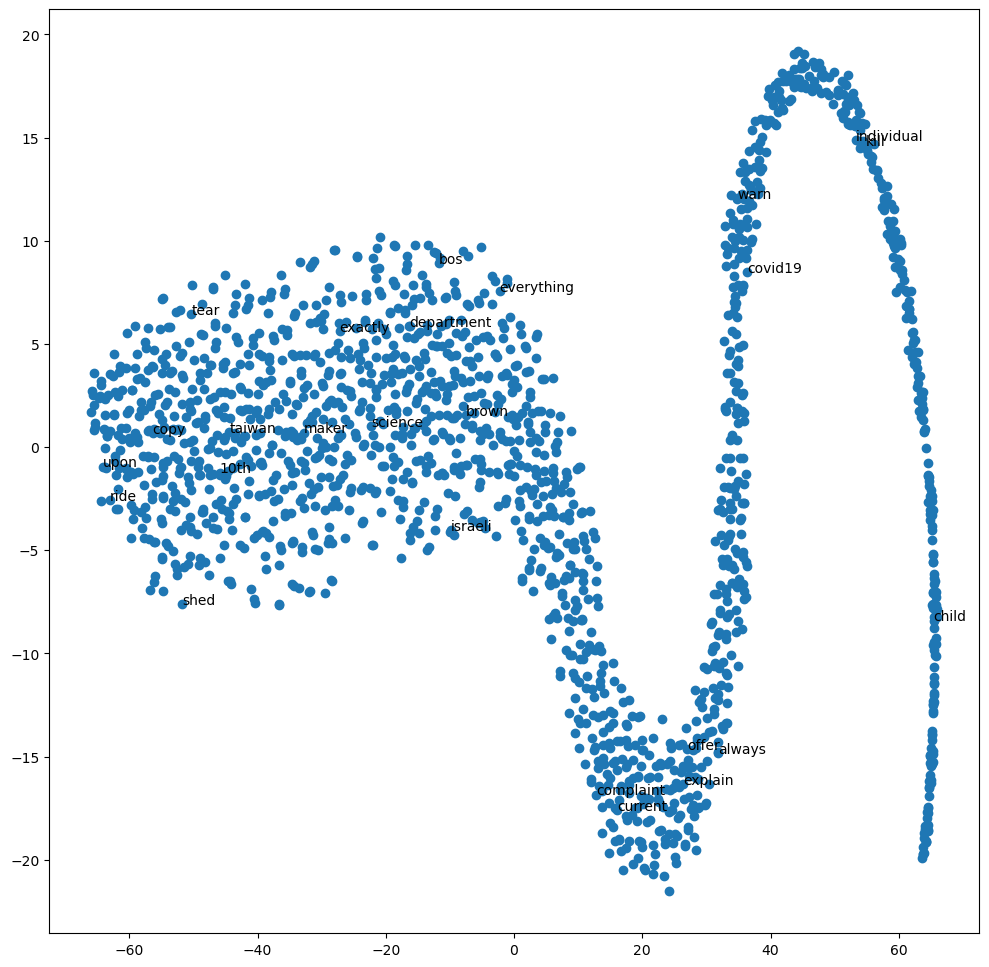

In [92]:
from sklearn.decomposition import IncrementalPCA    # inital reduction
from sklearn.manifold import TSNE                   # final reduction
import numpy as np                                  # array handling


def reduce_dimensions(model):
    num_dimensions = 2  # final num dimensions (2D, 3D, etc)

    # extract the words & their vectors, as numpy arrays
    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)  # fixed-width numpy strings

    # reduce using t-SNE
    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    x_vals = [v[0] for v in vectors]
    y_vals = [v[1] for v in vectors]
    return x_vals, y_vals, labels


x_vals, y_vals, labels = reduce_dimensions(w2v_model)

def plot_with_plotly(x_vals, y_vals, labels, plot_in_notebook=True):
    from plotly.offline import init_notebook_mode, iplot, plot
    import plotly.graph_objs as go

    trace = go.Scatter(x=x_vals, y=y_vals, mode='text', text=labels)
    data = [trace]

    if plot_in_notebook:
        init_notebook_mode(connected=True)
        iplot(data, filename='word-embedding-plot')
    else:
        plot(data, filename='word-embedding-plot.html')


def plot_with_matplotlib(x_vals, y_vals, labels):
    import matplotlib.pyplot as plt
    import random

    random.seed(0)

    plt.figure(figsize=(12, 12))
    plt.scatter(x_vals, y_vals)

    #
    # Label randomly subsampled 25 data points
    #
    indices = list(range(len(labels)))
    selected_indices = random.sample(indices, 25)
    for i in selected_indices:
        plt.annotate(labels[i], (x_vals[i], y_vals[i]))

try:
    get_ipython()
except Exception:
    plot_function = plot_with_matplotlib
else:
    plot_function = plot_with_plotly

# plot_function(x_vals, y_vals, labels)
plot_with_matplotlib(x_vals, y_vals, labels)

### 2.1.3. Trees? LSTM?